## Two layer perceptron (MLP) to perform non-linear regression

Dataset: random variables mixed with gaussian noise

x: Single input feature

y: target

parameters: wh[1,16], bh[1,16], wo[16,1], bo[16,1] 

**Objective:** to find a line that best fits the input data points -> linear regression

- loss function: mean squared error since it is a regression
- AF: tanh (hyperbolic tangent activation function) in hidden layers; output layer- linear
- Numerical differentiation to find gradient
- wh, wo Matrix is initialized to a random numbers
- bh, bo matrix is initialized to 0
- perform mini batch gradient decent: 
- here the epoch = 1000 and batch size = 50



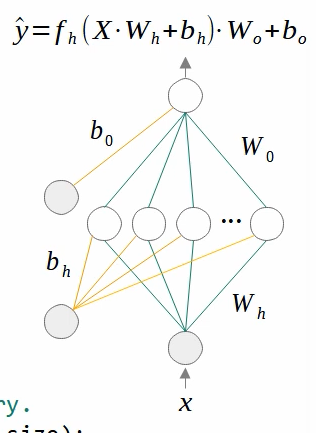

In [13]:
%load_ext autoreload
%autoreload 2
import numpy as np
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

from gradient_descent import gradient_descent

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
# [MXDL-1-07] 7.nonlinear_regression.py
# Create a two-layered ANN model and perform non-linear regression
# using numerical differentiation and gradient descent.


# Generate training data set
x = np.random.random((1000, 1))
y = 2.0 * np.sin(2.0 * np.pi * x) + \
    np.random.normal(0.0, 0.8, (1000, 1))

# Generate training, validation, and test data set
x_train, x_valid, y_train, y_valid = train_test_split(x, y)
x_test = np.linspace(0, 1, 200).reshape(-1, 1)

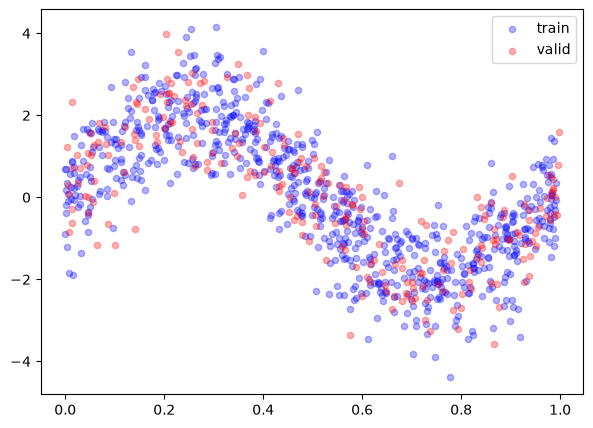

In [15]:
# See the data visually.
plt.figure(figsize=(7,5))
plt.scatter(x_train, y_train, s=20, c='blue', alpha=0.3,
            label='train')
plt.scatter(x_valid, y_valid, s=20, c='red', alpha=0.3,
            label='valid')
plt.legend()
plt.show()

In [16]:
# Create a two-layered ANN model.
n_input = x.shape[1]        # number of input neurons
n_output = 1                # number of output neurons
n_hidden = 16               # number of hidden1 neurons

alpha = 0.01
h = 1e-4

In [17]:
# initialize the parameters randomly.
wh = np.random.normal(size=(n_input, n_hidden))  # weights of hidden layer (1x16)
bh = np.zeros(shape=(1, n_hidden))               # biases of hidden layer (1x16)
wo = np.random.normal(size=(n_hidden, n_output)) # weights of output layer (16x1)
bo = np.zeros(shape=(1, n_output))               # bias of output layer(1x1)
parameters = [wh, bh, wo, bo]                    # parameter list

Just small changes in the predict function, but other than that, the training function is the same.

We are introducing another layer, the hedge out variable in predict function in order to calculate the activation function of the hidden layer output

0: train_loss=4.7672, val_loss=4.5852
10: train_loss=1.8246, val_loss=1.7704
20: train_loss=1.6310, val_loss=1.6001
30: train_loss=1.5597, val_loss=1.5367
40: train_loss=1.5347, val_loss=1.5172
50: train_loss=1.5227, val_loss=1.5087
60: train_loss=1.5205, val_loss=1.5060
70: train_loss=1.5135, val_loss=1.5000
80: train_loss=1.4973, val_loss=1.4914
90: train_loss=1.4885, val_loss=1.4883
100: train_loss=1.4758, val_loss=1.4737
110: train_loss=1.4622, val_loss=1.4615
120: train_loss=1.4473, val_loss=1.4470
130: train_loss=1.4320, val_loss=1.4321
140: train_loss=1.4143, val_loss=1.4222
150: train_loss=1.3967, val_loss=1.4062
160: train_loss=1.3898, val_loss=1.3841
170: train_loss=1.3531, val_loss=1.3568
180: train_loss=1.3339, val_loss=1.3341
190: train_loss=1.3116, val_loss=1.3213
200: train_loss=1.2906, val_loss=1.3012
210: train_loss=1.2724, val_loss=1.2742
220: train_loss=1.2481, val_loss=1.2554
230: train_loss=1.2414, val_loss=1.2569
240: train_loss=1.2374, val_loss=1.2579
250: train_

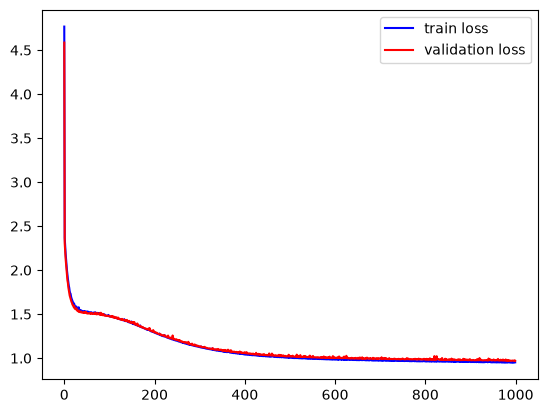

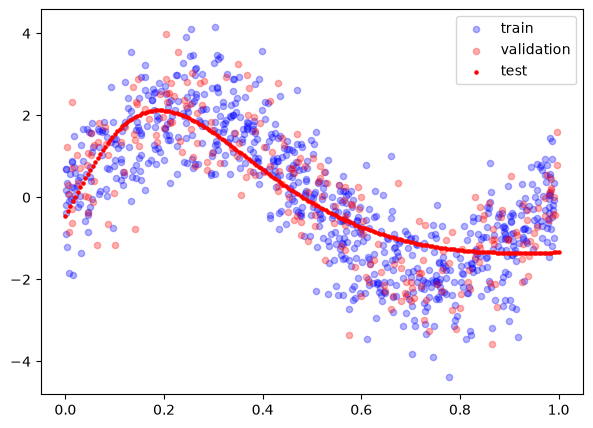

In [18]:
# loss function: mean squared error
def loss(y, y_hat):
    return np.mean(np.square(y - y_hat))

# Output from the ANN model: prediction process
def predict(x):
    p = parameters
    h_out = np.tanh(np.dot(x, p[0] + p[1]))
    o_out = np.dot(h_out, p[2]) + p[3]  # output from output layer
    return o_out

# Perform training and track the loss history.
def train(x, y, x_val, y_val, epochs, batch_size):
    ht_loss = []  # loss history of training data
    hv_loss = []  # loss history of validation data
    for epoch in range(epochs):
        # measure the losses during training
        ht_loss.append(loss(y, predict(x)))
        hv_loss.append(loss(y_val, predict(x_val)))
        # Perform training using mini-batch gradient descent
        for batch in range(int(x.shape[0] / batch_size)):
            idx = np.random.choice(x.shape[0], batch_size)
            gradient_descent(x[idx], y[idx], alpha, loss,
                             predict, parameters)

        if epoch % 10 == 0:
            print("{}: train_loss={:.4f}, val_loss={:.4f}".\
                  format(epoch, ht_loss[-1], hv_loss[-1]))
    return ht_loss, hv_loss

# Perform training
train_loss, val_loss = train(x_train, y_train, x_valid, y_valid,
                             epochs=1000, batch_size=50)

# Visually check the loss history.
plt.plot(train_loss, c='blue', label='train loss')
plt.plot(val_loss, c='red', label='validation loss')
plt.legend()
plt.show()

# Visually check the prediction result.
y_pred = predict(x_test)

plt.figure(figsize=(7,5))
plt.scatter(x_train, y_train, s=20, c='blue', alpha=0.3,
            label='train')
plt.scatter(x_valid, y_valid, s=20, c='red', alpha=0.3,
            label='validation')
plt.scatter(x_test, y_pred, s=5, c='red', label='test')
plt.legend()
plt.show()

# observation
As the iteration progresses, the loss decreases significantly, and the non-linear cove is able to fit the regression data properly.